In [18]:
# ============================================================
# Assignment 5
# Implement and Compare RNN, LSTM and GRU Models for Sequence Classification
# ============================================================

# ============================================================
# Part 1: Import Required Libraries
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, LSTM, GRU, Dense, Dropout
from sklearn.metrics import classification_report, confusion_matrix

In [19]:
# ============================================================
# Part 2: Load the IMDb Dataset
# ============================================================

# Number of most frequent words to keep
VOCAB_SIZE = 10000

# Maximum length of each review
MAX_LENGTH = 200

# Load IMDb dataset
(X_train, y_train), (X_test, y_test) = imdb.load_data(
    num_words=VOCAB_SIZE
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 25000
Testing samples: 25000


In [20]:
# ============================================================
# Part 3: Data Preprocessing
# ============================================================

# Reviews have different lengths.
# Padding makes all reviews the same length.

X_train = pad_sequences(
    X_train,
    maxlen=MAX_LENGTH,
    padding="post",
    truncating="post"
)

X_test = pad_sequences(
    X_test,
    maxlen=MAX_LENGTH,
    padding="post",
    truncating="post"
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

Training data shape: (25000, 200)
Testing data shape: (25000, 200)


In [21]:
# ============================================================
# Part 4: Function to Create RNN Model
# ============================================================

def create_rnn_model():

    model = Sequential([
        Embedding(
            input_dim=VOCAB_SIZE,
            output_dim=64,
            input_length=MAX_LENGTH
        ),

        SimpleRNN(64),

        Dropout(0.5),

        Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model

In [22]:
# ============================================================
# Part 5: Function to Create LSTM Model
# ============================================================

def create_lstm_model():

    model = Sequential([
        Embedding(
            input_dim=VOCAB_SIZE,
            output_dim=64,
            input_length=MAX_LENGTH
        ),

        LSTM(64),

        Dropout(0.5),

        Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model

In [23]:
# ============================================================
# Part 6: Function to Create GRU Model
# ============================================================

def create_gru_model():

    model = Sequential([
        Embedding(
            input_dim=VOCAB_SIZE,
            output_dim=64,
            input_length=MAX_LENGTH
        ),

        GRU(64),

        Dropout(0.5),

        Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model

In [24]:
# ============================================================
# Part 7: Train RNN Model
# ============================================================

print("\n================ RNN MODEL ================\n")

rnn_model = create_rnn_model()

rnn_model.summary()

rnn_history = rnn_model.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.2,
    verbose=1
)


================ RNN MODEL ================



d:\Manthan\Vit Btech\Vit TY\Sem 5\Deep Learning\Lab\DL_Lab\Lib\site-packages\keras\src\layers\core\embedding.py:123: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - accuracy: 0.5013 - loss: 0.7066 - val_accuracy: 0.5062 - val_loss: 0.7022
Epoch 2/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.5046 - loss: 0.7028 - val_accuracy: 0.4990 - val_loss: 0.6936
Epoch 3/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.5242 - loss: 0.6928 - val_accuracy: 0.5074 - val_loss: 0.6928
Epoch 4/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.5712 - loss: 0.6761 - val_accuracy: 0.5142 - val_loss: 0.6942
Epoch 5/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.6294 - loss: 0.6178 - val_accuracy: 0.5488 - val_loss: 0.7234


In [25]:
# ============================================================
# Part 8: Train LSTM Model
# ============================================================

print("\n================ LSTM MODEL ================\n")

lstm_model = create_lstm_model()

lstm_model.summary()

lstm_history = lstm_model.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.2,
    verbose=1
)


================ LSTM MODEL ================



Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_4 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 13s 39ms/step - accuracy: 0.5335 - loss: 0.6884 - val_accuracy: 0.5850 - val_loss: 0.6615
Epoch 2/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 12s 37ms/step - accuracy: 0.6272 - loss: 0.6555 - val_accuracy: 0.5294 - val_loss: 0.6756
Epoch 3/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 12s 39ms/step - accuracy: 0.7158 - loss: 0.5911 - val_accuracy: 0.5756 - val_loss: 0.6997
Epoch 4/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 12s 40ms/step - accuracy: 0.7381 - loss: 0.5615 - val_accuracy: 0.5676 - val_loss: 0.6775
Epoch 5/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 13s 42ms/step - accuracy: 0.7055 - loss: 0.5614 - val_accuracy: 0.8018 - val_loss: 0.4382


In [26]:
# ============================================================
# Part 9: Train GRU Model
# ============================================================

print("\n================ GRU MODEL ================\n")

gru_model = create_gru_model()

gru_model.summary()

gru_history = gru_model.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.2,
    verbose=1
)


================ GRU MODEL ================



Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_5 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 15s 44ms/step - accuracy: 0.5102 - loss: 0.6929 - val_accuracy: 0.5244 - val_loss: 0.6919
Epoch 2/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 14s 44ms/step - accuracy: 0.6094 - loss: 0.6554 - val_accuracy: 0.5504 - val_loss: 0.6779
Epoch 3/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 14s 43ms/step - accuracy: 0.6872 - loss: 0.6059 - val_accuracy: 0.7240 - val_loss: 0.5791
Epoch 4/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 14s 44ms/step - accuracy: 0.7572 - loss: 0.5338 - val_accuracy: 0.7354 - val_loss: 0.6551
Epoch 5/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 14s 44ms/step - accuracy: 0.6945 - loss: 0.5770 - val_accuracy: 0.5288 - val_loss: 0.6817


In [27]:
# ============================================================
# Part 10: Evaluate All Models
# ============================================================

rnn_loss, rnn_accuracy = rnn_model.evaluate(
    X_test,
    y_test,
    verbose=0
)

lstm_loss, lstm_accuracy = lstm_model.evaluate(
    X_test,
    y_test,
    verbose=0
)

gru_loss, gru_accuracy = gru_model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("\n================ MODEL COMPARISON ================\n")

print("RNN  Test Accuracy :", round(rnn_accuracy * 100, 2), "%")
print("LSTM Test Accuracy :", round(lstm_accuracy * 100, 2), "%")
print("GRU  Test Accuracy :", round(gru_accuracy * 100, 2), "%")


================ MODEL COMPARISON ================

RNN  Test Accuracy : 53.17 %
LSTM Test Accuracy : 79.3 %
GRU  Test Accuracy : 51.82 %


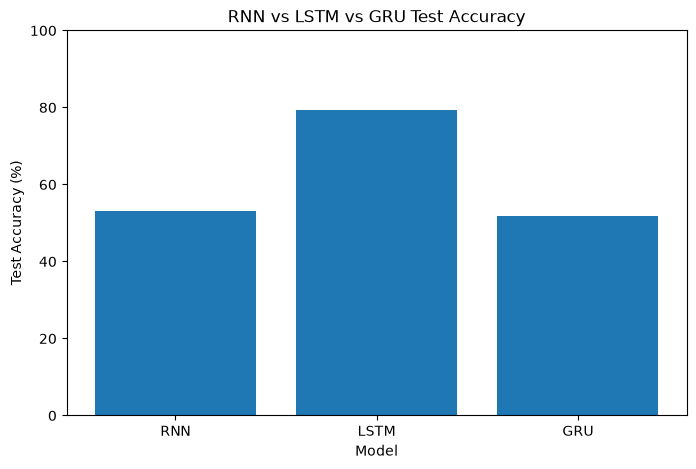

In [28]:
# ============================================================
# Part 11: Compare Accuracy
# ============================================================

models_name = ["RNN", "LSTM", "GRU"]

accuracy_values = [
    rnn_accuracy * 100,
    lstm_accuracy * 100,
    gru_accuracy * 100
]

plt.figure(figsize=(8, 5))

plt.bar(models_name, accuracy_values)

plt.xlabel("Model")
plt.ylabel("Test Accuracy (%)")
plt.title("RNN vs LSTM vs GRU Test Accuracy")

plt.ylim(0, 100)

plt.show()

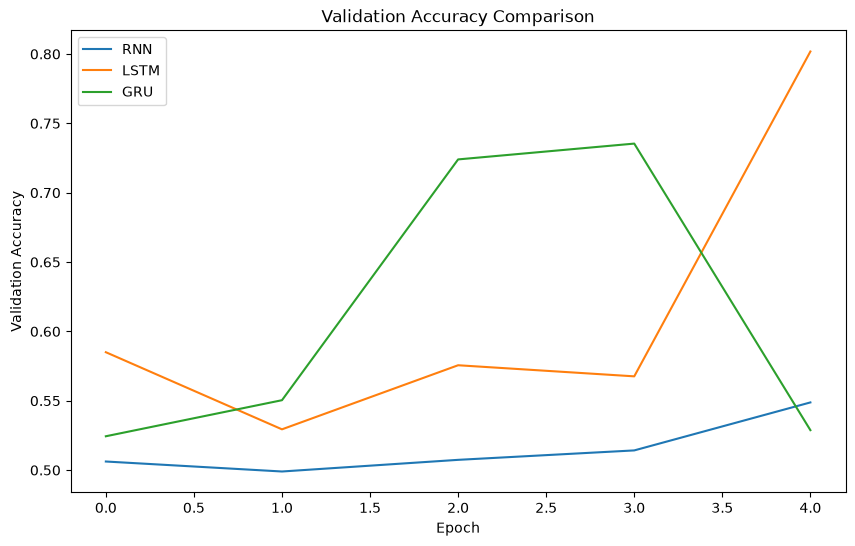

In [29]:
# ============================================================
# Part 12: Compare Validation Accuracy
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    rnn_history.history["val_accuracy"],
    label="RNN"
)

plt.plot(
    lstm_history.history["val_accuracy"],
    label="LSTM"
)

plt.plot(
    gru_history.history["val_accuracy"],
    label="GRU"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")

plt.title("Validation Accuracy Comparison")

plt.legend()

plt.show()

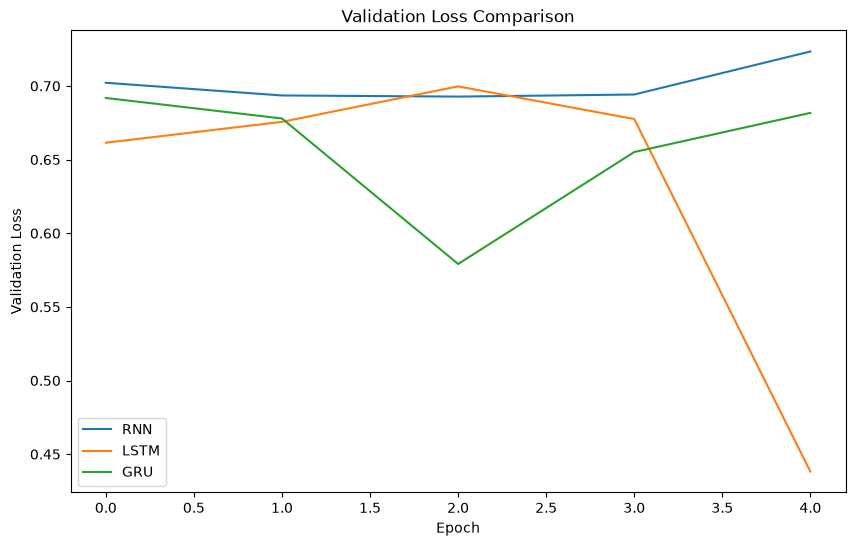

In [30]:
# ============================================================
# Part 13: Compare Validation Loss
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    rnn_history.history["val_loss"],
    label="RNN"
)

plt.plot(
    lstm_history.history["val_loss"],
    label="LSTM"
)

plt.plot(
    gru_history.history["val_loss"],
    label="GRU"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Loss")

plt.title("Validation Loss Comparison")

plt.legend()

plt.show()

In [31]:
# ============================================================
# Part 14: Classification Report
# ============================================================

# Generate predictions

rnn_predictions = (
    rnn_model.predict(X_test, verbose=0) >= 0.5
).astype(int).flatten()

lstm_predictions = (
    lstm_model.predict(X_test, verbose=0) >= 0.5
).astype(int).flatten()

gru_predictions = (
    gru_model.predict(X_test, verbose=0) >= 0.5
).astype(int).flatten()


print("\n================ RNN CLASSIFICATION REPORT ================\n")

print(
    classification_report(
        y_test,
        rnn_predictions,
        target_names=["Negative", "Positive"]
    )
)


print("\n================ LSTM CLASSIFICATION REPORT ================\n")

print(
    classification_report(
        y_test,
        lstm_predictions,
        target_names=["Negative", "Positive"]
    )
)


print("\n================ GRU CLASSIFICATION REPORT ================\n")

print(
    classification_report(
        y_test,
        gru_predictions,
        target_names=["Negative", "Positive"]
    )
)


================ RNN CLASSIFICATION REPORT ================

              precision    recall  f1-score   support

    Negative       0.52      0.77      0.62     12500
    Positive       0.56      0.29      0.38     12500

    accuracy                           0.53     25000
   macro avg       0.54      0.53      0.50     25000
weighted avg       0.54      0.53      0.50     25000


================ LSTM CLASSIFICATION REPORT ================

              precision    recall  f1-score   support

    Negative       0.86      0.70      0.77     12500
    Positive       0.75      0.88      0.81     12500

    accuracy                           0.79     25000
   macro avg       0.80      0.79      0.79     25000
weighted avg       0.80      0.79      0.79     25000


================ GRU CLASSIFICATION REPORT ================

              precision    recall  f1-score   support

    Negative       0.51      0.79      0.62     12500
    Positive       0.54      0.25      0.34     12

In [32]:
# ============================================================
# Part 15: Confusion Matrices
# ============================================================

print("\nRNN Confusion Matrix:")
print(confusion_matrix(y_test, rnn_predictions))

print("\nLSTM Confusion Matrix:")
print(confusion_matrix(y_test, lstm_predictions))

print("\nGRU Confusion Matrix:")
print(confusion_matrix(y_test, gru_predictions))


RNN Confusion Matrix:
[[9630 2870]
 [8837 3663]]

LSTM Confusion Matrix:
[[ 8792  3708]
 [ 1467 11033]]

GRU Confusion Matrix:
[[9816 2684]
 [9362 3138]]


In [33]:
# ============================================================
# Part 16: Final Comparison Table
# ============================================================

print("\n================ FINAL RESULTS ================\n")

print("Model\t\tTest Accuracy")
print("--------------------------------")

print(
    "RNN\t\t",
    round(rnn_accuracy * 100, 2),
    "%"
)

print(
    "LSTM\t\t",
    round(lstm_accuracy * 100, 2),
    "%"
)

print(
    "GRU\t\t",
    round(gru_accuracy * 100, 2),
    "%"
)


================ FINAL RESULTS ================

Model		Test Accuracy
--------------------------------
RNN		 53.17 %
LSTM		 79.3 %
GRU		 51.82 %


In [34]:
# ============================================================
# Part 17: Save Models
# ============================================================

rnn_model.save("rnn_model.keras")
lstm_model.save("lstm_model.keras")
gru_model.save("gru_model.keras")

print("\nAll three models saved successfully.")



All three models saved successfully.
